# Exercise 1: Heredero Louis & Amacker Olivier

## PRACTICAL WORK: RANDOM FOREST AND OTHER DECISION TREES-BASED ENSEMBLE LEARNING METHODS

In this practical work, we will explore the application of classification trees and random forests in analyzing a dataset about mice's sleep obtained from CHUV. This dataset includes the Electroencephalogram (EEG) of a mouse, as well as its state. The state of the mouse can be either awake, in REM sleep, or in non-REM sleep (REM and non-REM are two distinct stages of sleep that make up the sleep cycle). The goal will be to predict the state of the mouse based on its EEG. 


EEG is a scientific tool that helps us study brain activity. It records the electrical signals in the brain over time, creating a time serie with detailed patterns. These patterns include things like alpha oscillations suggesting a relaxed but awake state, beta oscillations that might indicate active thinking and focus, or theta oscillations typically observed during deep sleep and non-REM sleep stages.

The problem is that the information about these patterns is spread out over many data points, making it hard to detect directly the main frequency of such oscillations. So, we use something called spectral analysis, which transforms these time series into a different view called the frequency domain. This helps us see the main patterns more clearly by concentrating information about one frequency of oscillation. The process of converting data from the time-domain to the frequency-domain is done thanks to Fourier transforms.

### IMPORTS AND FUNCTIONS

In [1]:
# IMPORTS PACKAGES
import os

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.stats import randint
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

## DATA EXPLORATION

Let's look a bit closer at our data. A row was generated each 4 seconds (=15 by minute) during one entire day, giving a dataset of 15x60x24=21600 datapoints. After removing outliers, we are left with 20258 datapoints. For each of this datapoint, the mouse is either awake (w), in REM sleep (r), or in non-REM sleep (n).

In addition to its current state, each datapoint (row) is characterized with an EEG value as well as a "spectrum". EEGv represents the raw electrical activity of the mouse's brain at this timestamp. As mentionned earlier, it is really difficult to use it as such. This is why we will focus on the spectrum in order to predict the state of the mouse. The spectrum is described as the amplitude of the signal at each frequency between 1 and 100 [Hz] during the last 4 seconds (=since the last datapoint).

The main point to understand is that at each timestamp (= row = datapoint), the mouse is in a specific state and its brain electrical activity is represented by 100 different features based on frequencies.

In [2]:
path = os.path.join(os.getcwd(), "EEG_mouse_data.csv")
data_mice = pd.read_csv(path)
data_mice

,EEGv,state,amplitude_around_1_Hertz,amplitude_around_2_Hertz,amplitude_around_3_Hertz,amplitude_around_4_Hertz,amplitude_around_5_Hertz,amplitude_around_6_Hertz,amplitude_around_7_Hertz,amplitude_around_8_Hertz,...,amplitude_around_92_Hertz,amplitude_around_93_Hertz,amplitude_around_94_Hertz,amplitude_around_95_Hertz,amplitude_around_96_Hertz,amplitude_around_97_Hertz,amplitude_around_98_Hertz,amplitude_around_99_Hertz,amplitude_around_100_Hertz,amplitude_around_101_Hertz
0,6.141060e-09,n,0.000009,0.000014,0.000013,0.000014,0.000023,0.000009,0.000019,0.000011,...,8.364060e-09,4.208368e-09,2.177679e-09,4.342505e-09,5.130010e-09,2.852361e-09,9.772395e-10,1.876307e-09,5.457793e-09,8.653900e-08
1,6.382520e-09,n,0.000010,0.000010,0.000011,0.000015,0.000022,0.000017,0.000027,0.000011,...,6.695745e-09,1.213822e-08,2.287185e-08,3.219380e-09,2.461736e-09,2.985953e-09,1.434412e-09,1.579590e-09,5.458902e-09,8.492570e-08
2,6.351610e-09,n,0.000011,0.000077,0.000034,0.000019,0.000013,0.000006,0.000010,0.000004,...,1.105705e-08,3.264479e-09,1.204057e-09,5.090074e-09,5.477467e-09,1.809223e-09,7.064289e-10,1.435585e-09,7.416121e-09,1.156240e-07
3,4.961502e-09,w,0.000003,0.000031,0.000044,0.000016,0.000007,0.000006,0.000005,0.000007,...,2.223992e-08,1.028462e-08,3.561479e-09,3.704753e-09,2.425319e-09,1.536834e-09,2.540238e-10,6.300358e-10,3.647454e-09,2.212800e-08
4,7.170600e-09,w,0.000010,0.000011,0.000012,0.000017,0.000020,0.000018,0.000014,0.000025,...,6.541705e-09,3.312024e-09,8.779863e-09,7.400000e-09,2.890853e-09,5.709757e-10,2.171227e-09,6.757242e-10,2.005702e-09,2.861980e-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20253,6.150660e-09,n,0.000005,0.000008,0.000012,0.000007,0.000013,0.000010,0.000018,0.000017,...,5.183056e-09,9.379552e-09,1.978565e-08,8.485186e-09,8.522990e-09,3.671670e-09,3.326887e-09,7.048883e-10,1.659072e-09,1.391190e-10
20254,5.861332e-09,n,0.000035,0.000051,0.000024,0.000011,0.000012,0.000008,0.000008,0.000005,...,6.857218e-09,7.720315e-09,7.999804e-09,6.056920e-09,2.237395e-09,4.055173e-09,5.554118e-10,2.438095e-09,7.414557e-10,1.556200e-09
20255,5.270140e-09,n,0.000008,0.000008,0.000007,0.000037,0.000035,0.000020,0.000028,0.000007,...,6.150013e-09,7.243945e-09,5.711502e-09,5.689413e-09,5.574070e-09,3.924516e-09,2.758703e-09,1.446737e-09,8.830650e-10,9.809770e-10
20256,7.092485e-09,n,0.000021,0.000038,0.000039,0.000020,0.000030,0.000011,0.000009,0.000007,...,9.780405e-09,3.613270e-09,7.738320e-10,1.116278e-08,3.097371e-09,3.617548e-09,1.286851e-09,3.688830e-10,2.663532e-09,6.367370e-09


On the figure below, you can see a few examples of spectrum for each of the three classes.

Q1.1: At which frequencies does the electrical activity mostly occur?

**A1.1**Mostly between 0-10 HZ

Q1.2: Can you easily distinguish between classes visually? What can you say about the inter- vs intra-class variability?  

**A1.2** Not really, the n and w spectrum are quite similar in 2nd row

intra-class variability is large compared to inter-class differences

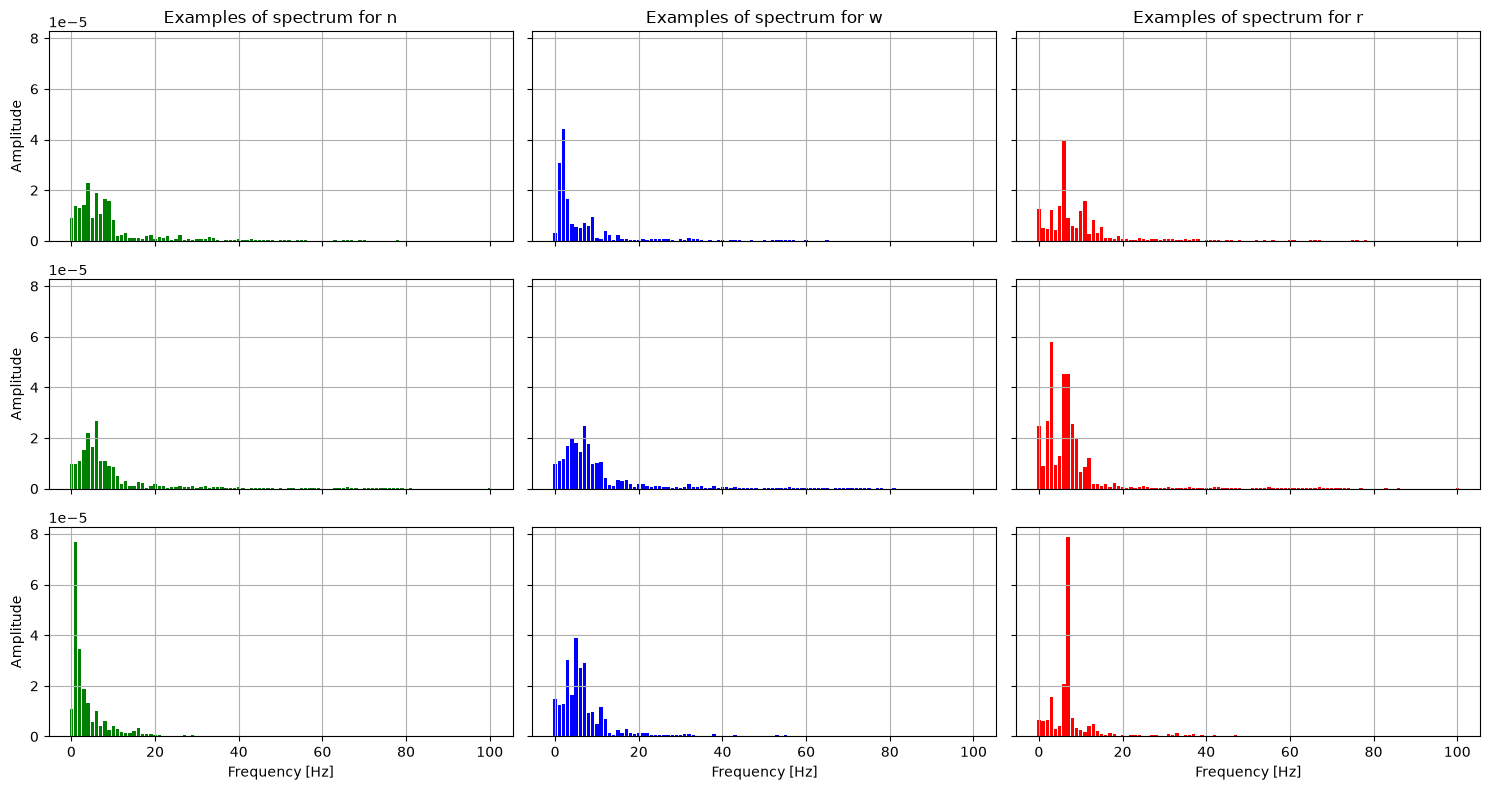

In [3]:
# Get unique states in the "state" column
unique_states = data_mice["state"].unique()

# Set up a color map for each state
color_map = {"w": "blue", "n": "green", "r": "red"}

# Create a figure with a 3x3 grid of subplots
fig, axs = plt.subplots(3, 3, figsize=(15, 8), sharey=True, sharex=True)

# Iterate over rows
for i in range(3):
    # Iterate over states
    for j, state in enumerate(unique_states):
        # Filter the data for the current state
        state_data = data_mice[data_mice["state"] == state].iloc[i, 2:]

        # Create a bar plot for the current state with the corresponding color
        axs[i, j].bar(
            np.arange(len(state_data)), state_data, color=color_map[state], width=0.8
        )
        axs[j, i].grid()

        # Set labels for the first row of subplots
        if i == 0:
            axs[i, j].set_title(f"Examples of spectrum for {state}")

# Set common labels
for i in range(3):
    axs[i, 0].set_ylabel("Amplitude")
for j in range(3):
    axs[2, j].set_xlabel("Frequency [Hz]")

plt.tight_layout()
plt.show()

## DECISION TREE

We will now build our first models to predict the state of the mouse. In order to do that, we will create X (=input) and Y (=target), normalize X, and split the dataset into a train and a test set.

In this notebook, we will use single decision tree classifiers. In the next notebook, we will be looking at random forests and other ensembles of decision trees.

In [4]:
# CREATE X AND Y FROM DATAFRAME / NORMALIZE X / SPLIT THE DATA INTO TRAIN/TEST
X = data_mice.drop(["EEGv", "state"], axis=1).to_numpy()
X = MinMaxScaler().fit_transform(X)
Y = data_mice["state"].values

# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

#### Model 1

Model 1 is a very basic decision tree implemented with the sklearn library. Main criteria to determine how to split the data at each node include gini impurity and entropy.

Q1.3: Describe both of these criteria. What does a gini impurity of 0 means? What does an entropy of 1 mean?

**A1.3** A gini impurity of 0 means that all samples belongs in 1 class (it's best value possible)

An entropy of 1 means that the split splits the classes exactly 50/50 meaning it's the worst value possible

In [5]:
# Create and train a DecisionTreeClassifier
criterion = "gini"  #'entropy'#
DecisionTree_clf = DecisionTreeClassifier(criterion=criterion)
DecisionTree_clf = DecisionTree_clf.fit(X_train, Y_train)

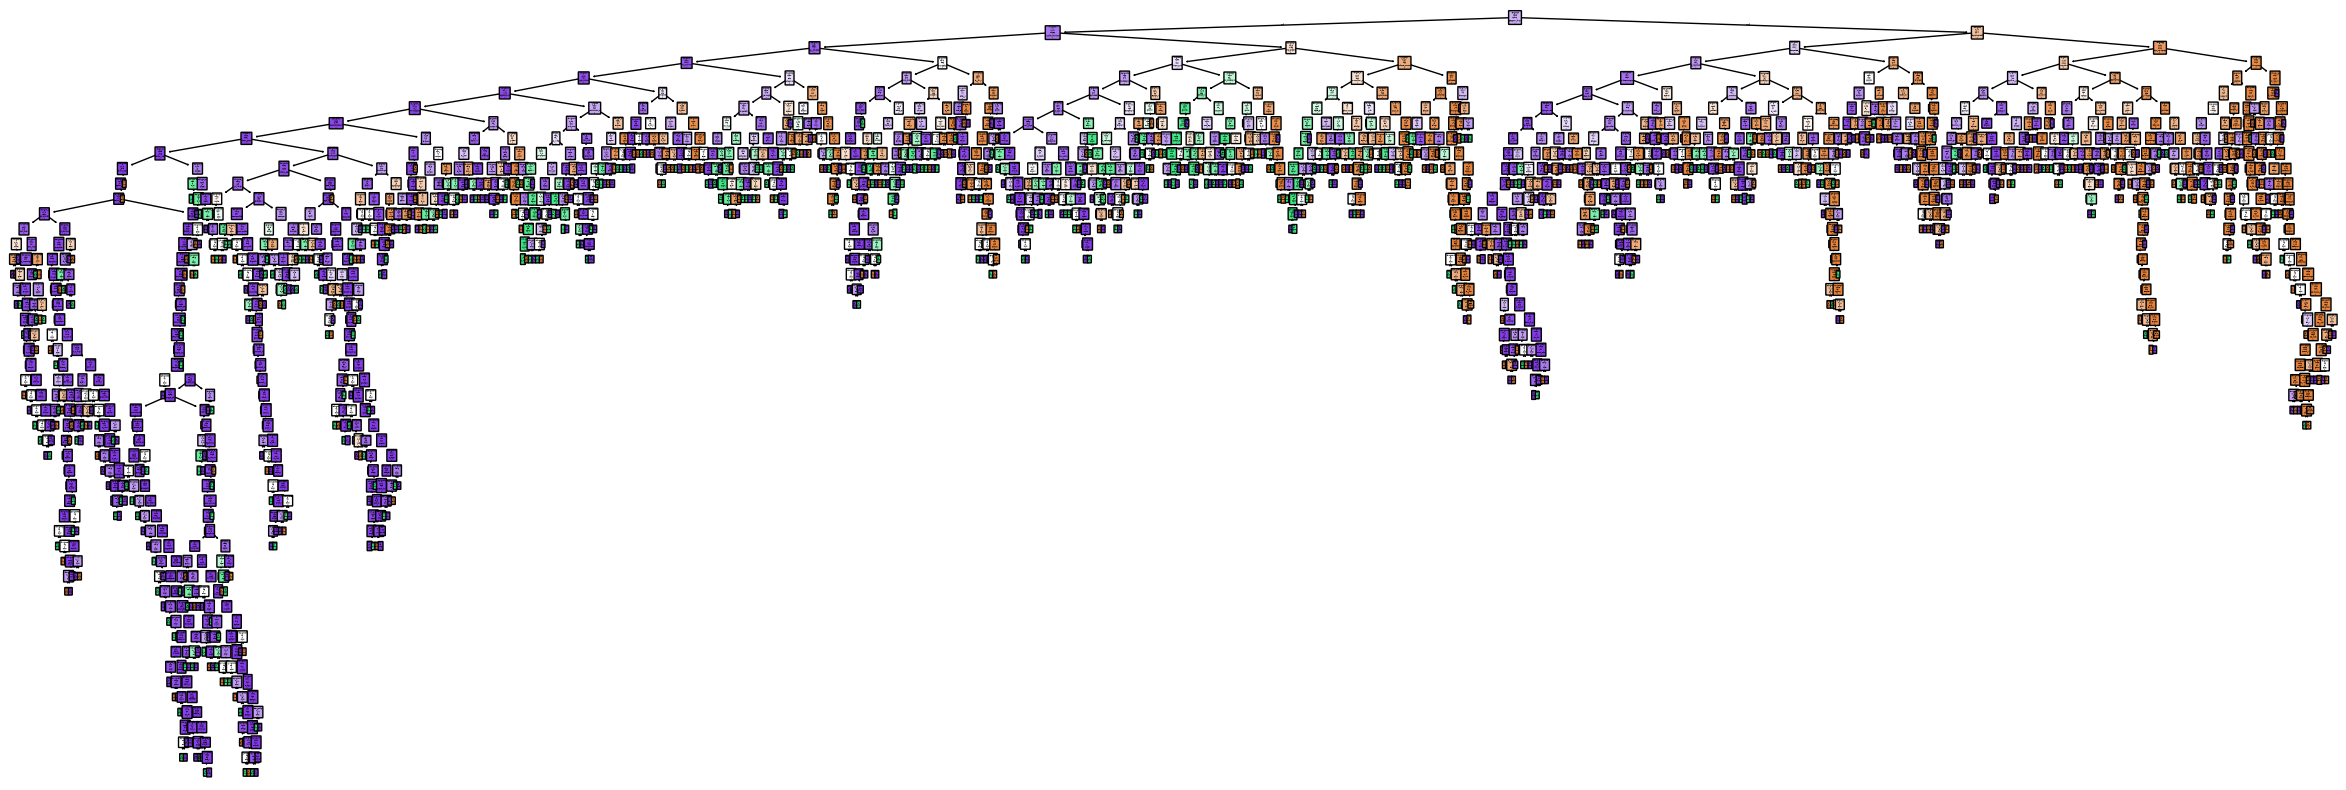

In [6]:
# Visualize model1 (it might take a bit of time as this tree is very big)
fig, ax = plt.subplots(figsize=(30, 10))  # figsize=(50, 25)
tree_plot = plot_tree(
    DecisionTree_clf,
    filled=True,
    feature_names=None,
    class_names=list(DecisionTree_clf.classes_),
    rounded=True,
    label="none",
)  # , fontsize=12
plt.show()

Accuracy on Training Set: 1.0
Accuracy on Test Set: 0.8050345508390918
Classification Report for Training Set:
              precision  recall  f1-score  support
n                   1.0     1.0       1.0   5365.0
r                   1.0     1.0       1.0   1074.0
w                   1.0     1.0       1.0   9767.0
accuracy            1.0     1.0       1.0      1.0
macro avg           1.0     1.0       1.0  16206.0
weighted avg        1.0     1.0       1.0  16206.0
Classification Report for Test Set:
              precision    recall  f1-score      support
n              0.806310  0.798692  0.802483  1376.000000
r              0.330961  0.343173  0.336957   271.000000
w              0.859635  0.860707  0.860170  2405.000000
accuracy       0.805035  0.805035  0.805035     0.805035
macro avg      0.665635  0.667524  0.666537  4052.000000
weighted avg   0.806168  0.805035  0.805588  4052.000000


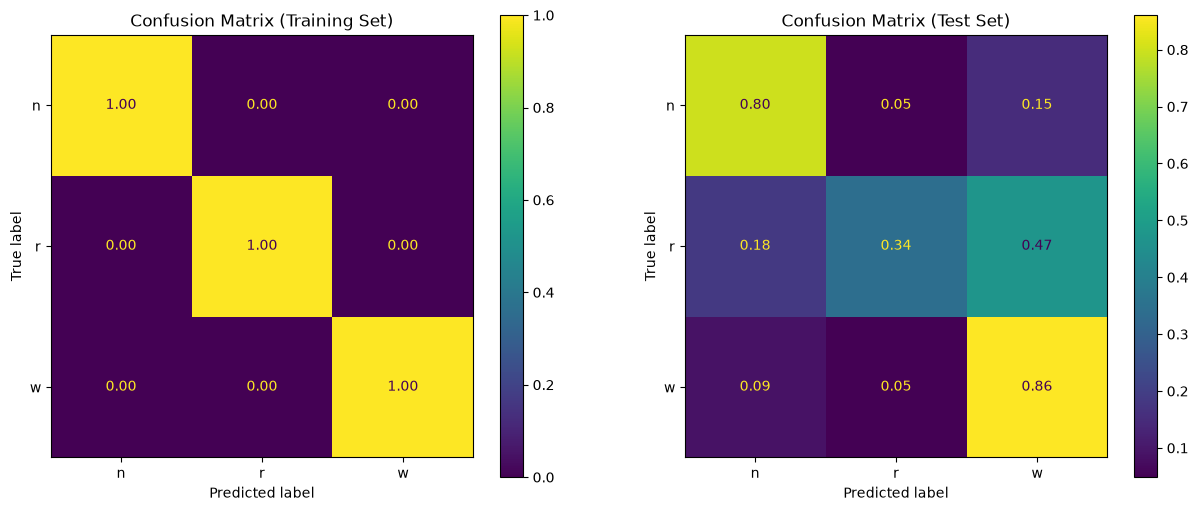

In [7]:
# Make predictions
train_prediction = DecisionTree_clf.predict(X_train)
test_prediction = DecisionTree_clf.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(Y_train, train_prediction)
test_accuracy = accuracy_score(Y_test, test_prediction)

# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Confusion matrix for the training set
cm_train = confusion_matrix(Y_train, train_prediction, normalize="true")
disp_train = ConfusionMatrixDisplay(
    confusion_matrix=cm_train, display_labels=DecisionTree_clf.classes_
)
_ = disp_train.plot(ax=axs[0], values_format=".2f")
_ = axs[0].set_title("Confusion Matrix (Training Set)")

# Confusion matrix for the test set
cm_test = confusion_matrix(Y_test, test_prediction, normalize="true")
disp_test = ConfusionMatrixDisplay(
    confusion_matrix=cm_test, display_labels=DecisionTree_clf.classes_
)
_ = disp_test.plot(ax=axs[1], values_format=".2f")
_ = axs[1].set_title("Confusion Matrix (Test Set)")

# Display accuracy for both sets
print("Accuracy on Training Set:", train_accuracy)
print("Accuracy on Test Set:", test_accuracy)

# Classification report for the training set
classification_metrics_train = classification_report(
    Y_train, train_prediction, output_dict=True
)
report_df_train = pd.DataFrame(classification_metrics_train).transpose()
print("Classification Report for Training Set:")
print(report_df_train)

# Classification report for the test set
classification_metrics_test = classification_report(
    Y_test, test_prediction, output_dict=True
)
report_df_test = pd.DataFrame(classification_metrics_test).transpose()
print("Classification Report for Test Set:")
print(report_df_test)

plt.show()

Q1.4: This problem suffers from a common issue in machine learning. What is this problem called? What could be its causes? How can it be resolved?

**A1.4**
The problem we observe here is called overfitting, the model gets a perfect score on the training data, but fails to generalize to the test data.

It is caused by either the model being too complex, therefore being able to learn the training data by heart

Here are some possible fixes

- Prune the tree
- Get more training data
- Reduce the number of features
- Use cross validation

#### Model 2

Model 2 introduces two additional hyperparameters: min_samples_leaf and max_depth.

In [8]:
# Create and train a DecisionTreeClassifier
criterion = "gini"
DecisionTree_clf2 = DecisionTreeClassifier(
    criterion=criterion, min_samples_leaf=20, max_depth=4
)  #
DecisionTree_clf2 = DecisionTree_clf2.fit(X_train, Y_train)

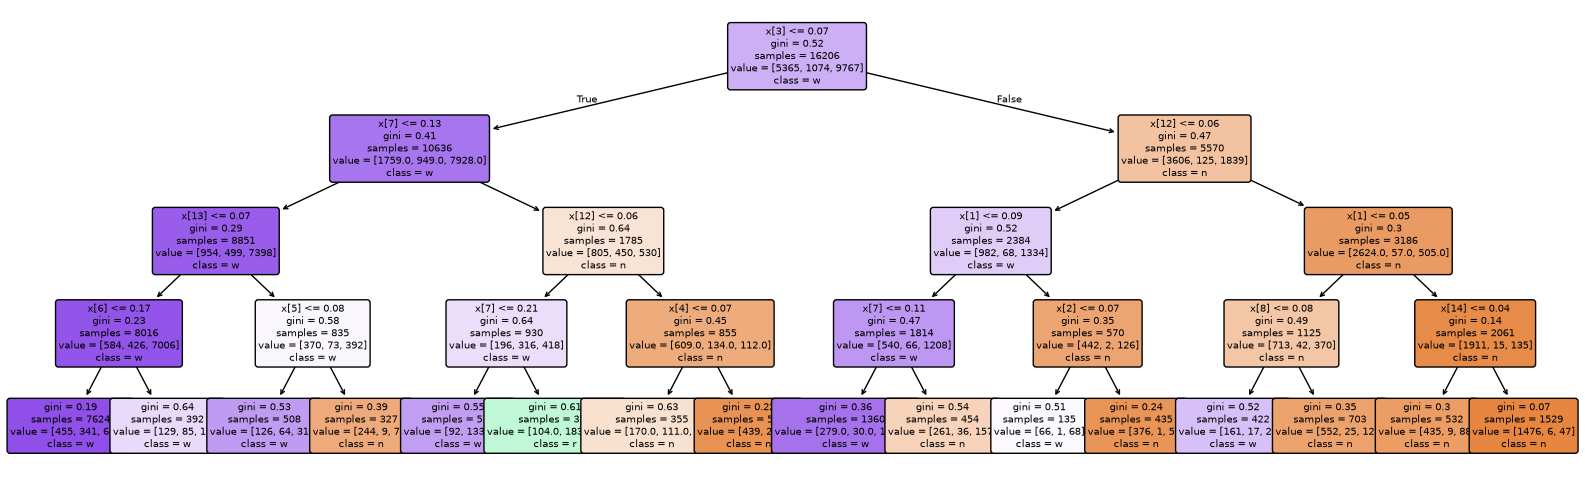

In [9]:
# Visualize model2
fig, ax = plt.subplots(figsize=(20, 6))  # figsize=(50, 25)
tree_plot = plot_tree(
    DecisionTree_clf2,
    filled=True,
    feature_names=None,
    class_names=list(DecisionTree_clf2.classes_),
    rounded=True,
    fontsize=7,
    precision=2,
)  #
plt.show()
fig.savefig("decision_tree_model2.png")

Q1.5: Use the visualization of this tree to show and explain:

- What is a node? What is an edge? What is a leaf?
    
    - A node is a point where the data is splitted based on a test for a specific criteria
    - An edge represent the output of this test
    - A leaf is a terminal node that outputs the predicted class
  

- What are the two additional hyperparameters doing? Do you think that both are necessary in this particular case (min_samples_leaf = 20, max_depth= 4)? Why?
    - `max_depth=4`stops the tree after it reaches a depth of 4. This avoids the tree becoming very large like in the first model
    - `min_samples_leaf=20` Forces each leaf to represent at least 20 samples, avoiding leafs that represent only a small part of the data

    I think that both are needed to some extend, seing the overfitting of the 1st model. However, it should take more experimenting and confusion matrices to chose their correct values.

- What does the color of each node represent?
    - The hue encodes the majority class
    - The entensity encodes the purity of the node (the strongest the purest)

Q1.6: Choose one of the nodes. Explain precisely the information given on each line of text in this node.

**A1.6**
Let's take the root left child. It containes the following information
  - `x[7] <= 0.13` is the actual test. It asks the question "is x[7] lower or equal to 0.13"
  - `gini = 0.41` is the value of the gini impurity for this node
  - `samples=10636` is the number of samples from the training data which reached this question
  - `value = [1759.0, 949.0, 7928.0]` is the repartition of the classes of the `10636` samples
  - `class=w`is the class of the majority of training sample who reached this node

Feel free to change min_samples_leaf and max_depth to explore their effects on the tree

Accuracy on Training Set: 0.8129087992101691
Accuracy on Test Set: 0.8121915103652517
Classification Report for Training Set:
              precision    recall  f1-score       support
n              0.817580  0.736813  0.775098   5365.000000
r              0.516949  0.170391  0.256303   1074.000000
w              0.820369  0.925361  0.869707   9767.000000
accuracy       0.812909  0.812909  0.812909      0.812909
macro avg      0.718299  0.610855  0.633703  16206.000000
weighted avg   0.799337  0.812909  0.797736  16206.000000
Classification Report for Test Set:
              precision    recall  f1-score      support
n              0.825371  0.728198  0.773745  1376.000000
r              0.567308  0.217712  0.314667   271.000000
w              0.815655  0.927235  0.867873  2405.000000
accuracy       0.812192  0.812192  0.812192     0.812192
macro avg      0.736111  0.624382  0.652095  4052.000000
weighted avg   0.802345  0.812192  0.798910  4052.000000


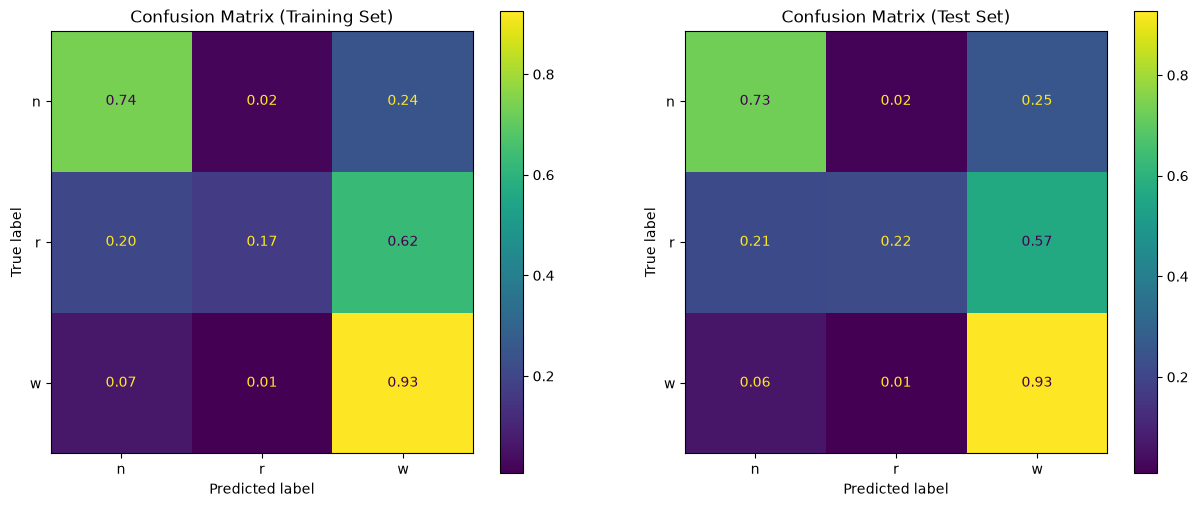

In [10]:
# Make predictions
train_prediction = DecisionTree_clf2.predict(X_train)
test_prediction = DecisionTree_clf2.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(Y_train, train_prediction)
test_accuracy = accuracy_score(Y_test, test_prediction)

# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Confusion matrix for the training set
cm_train = confusion_matrix(Y_train, train_prediction, normalize="true")
disp_train = ConfusionMatrixDisplay(
    confusion_matrix=cm_train, display_labels=DecisionTree_clf2.classes_
)
_ = disp_train.plot(ax=axs[0], values_format=".2f")
_ = axs[0].set_title("Confusion Matrix (Training Set)")

# Confusion matrix for the test set
cm_test = confusion_matrix(Y_test, test_prediction, normalize="true")
disp_test = ConfusionMatrixDisplay(
    confusion_matrix=cm_test, display_labels=DecisionTree_clf2.classes_
)
_ = disp_test.plot(ax=axs[1], values_format=".2f")
_ = axs[1].set_title("Confusion Matrix (Test Set)")

# Display accuracy for both sets
print("Accuracy on Training Set:", train_accuracy)
print("Accuracy on Test Set:", test_accuracy)

# Classification report for the training set
classification_metrics_train = classification_report(
    Y_train, train_prediction, output_dict=True, zero_division=0
)
report_df_train = pd.DataFrame(classification_metrics_train).transpose()
print("Classification Report for Training Set:")
print(report_df_train)

# Classification report for the test set
classification_metrics_test = classification_report(
    Y_test, test_prediction, output_dict=True, zero_division=0
)
report_df_test = pd.DataFrame(classification_metrics_test).transpose()
print("Classification Report for Test Set:")
print(report_df_test)

plt.show()

Q1.7: Does model 2 still have the same problem as model 1? Explain based on the classification reports and the confusion matrices.

**A1.7**

This model doesn't have an overfitting problem anymore. This is showed by the classification report, where the model has quite the same performances on the test data than on the train one. This is also showed in the confusion matrices

Q1.8: One of the class seems more difficult to predict than others? Which one? Where could this difficulty come from in your opinion?

**A1.8**

The model seems to strugle predicting class r, as shown on the confusion matrices. This is due to the initial class repartition of the `state` column not being balanced as shown on the under code cell

In [11]:
data_mice["state"].value_counts()

state
w    12172
n     6741
r     1345
Name: count, dtype: int64

#### Model 3

Model 3 is supposed to solve the difficulty encountered by model 2 thanks to class_weight='balanced'. 

Q1.9: What does this hyperparameter do ? Explain giving examples from this dataset.

**A1.9**
- The `class_weight='balanced'` parameter solves our class-imbalance problem (w: 12172, n: 6741, r: 1345) by computing Gini impurity with weighted class counts instead of raw counts, so that each class contributes equally to the criterion. The original criterion is

$$G = 1 - \sum_j \left(\frac{n_j}{N}\right)^2$$

And with the balanced weight $w_j = \frac{N}{3\,n_j}$ it becomes

$$G = 1 - \sum_j \left(\frac{w_j \, n_j}{\sum_k w_k \, n_k}\right)^2$$

Here is what it means for our dataset

| class | count | share | weight w\_j | weighted count |
| ----- | ----- | ----- | ----------- | -------------- |
| w     | 12172 | 60.1% | 0.55        | 6753           |
| n     | 6741  | 33.3% | 1.00        | 6753           |
| r     | 1345  | 6.6%  | 5.02        | 6753           |


In [12]:
# Create and train a DecisionTreeClassifier
criterion = "gini"
DecisionTree_clf3 = DecisionTreeClassifier(
    criterion=criterion, min_samples_leaf=20, max_depth=4, class_weight="balanced"
)
DecisionTree_clf3 = DecisionTree_clf3.fit(X_train, Y_train)

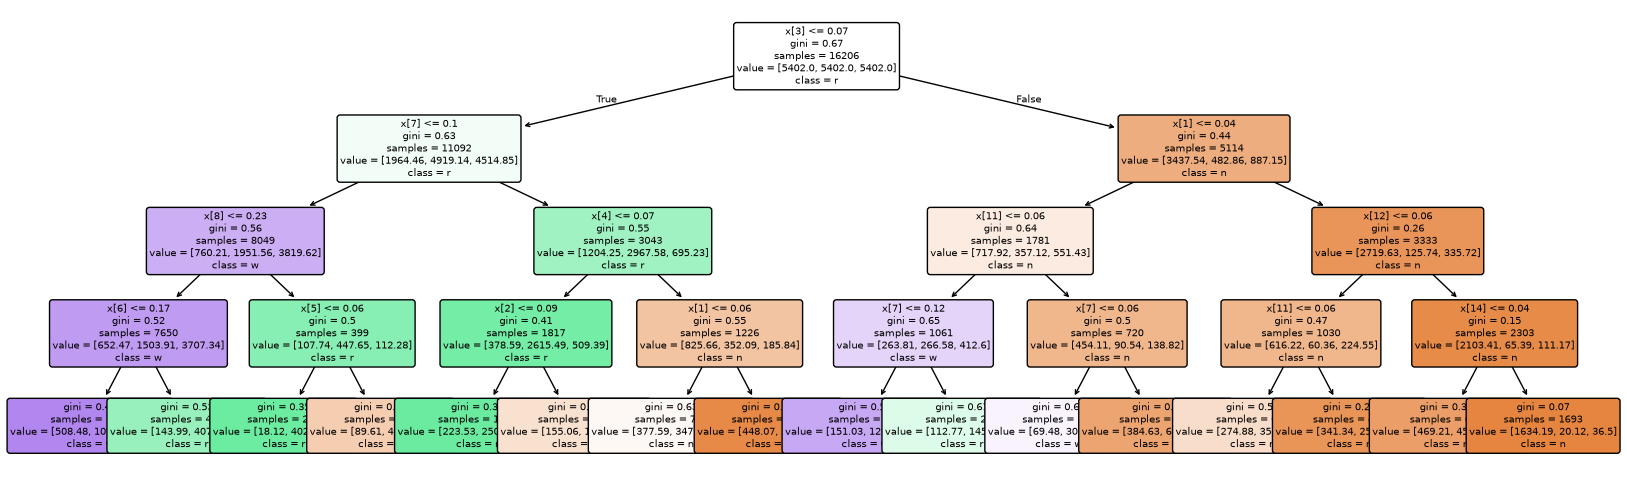

In [13]:
# Visualize model3
fig, ax = plt.subplots(figsize=(20, 6))
tree_plot = plot_tree(
    DecisionTree_clf3,
    filled=True,
    feature_names=None,
    class_names=list(DecisionTree_clf3.classes_),
    rounded=True,
    fontsize=7,
    precision=2,
)  #
plt.show()

Accuracy on Training Set: 0.7504010860175244
Accuracy on Test Set: 0.7495064165844028
Classification Report for Training Set:
              precision    recall  f1-score       support
n              0.756984  0.772787  0.764804   5365.000000
r              0.283422  0.641527  0.393153   1074.000000
w              0.882863  0.750077  0.811071   9767.000000
accuracy       0.750401  0.750401  0.750401      0.750401
macro avg      0.641090  0.721463  0.656342  16206.000000
weighted avg   0.801465  0.750401  0.768058  16206.000000
Classification Report for Test Set:
              precision    recall  f1-score      support
n              0.768459  0.779070  0.773728  1376.000000
r              0.266200  0.560886  0.361045   271.000000
w              0.869128  0.753846  0.807393  2405.000000
accuracy       0.749506  0.749506  0.749506     0.749506
macro avg      0.634595  0.697934  0.647389  4052.000000
weighted avg   0.794618  0.749506  0.766109  4052.000000


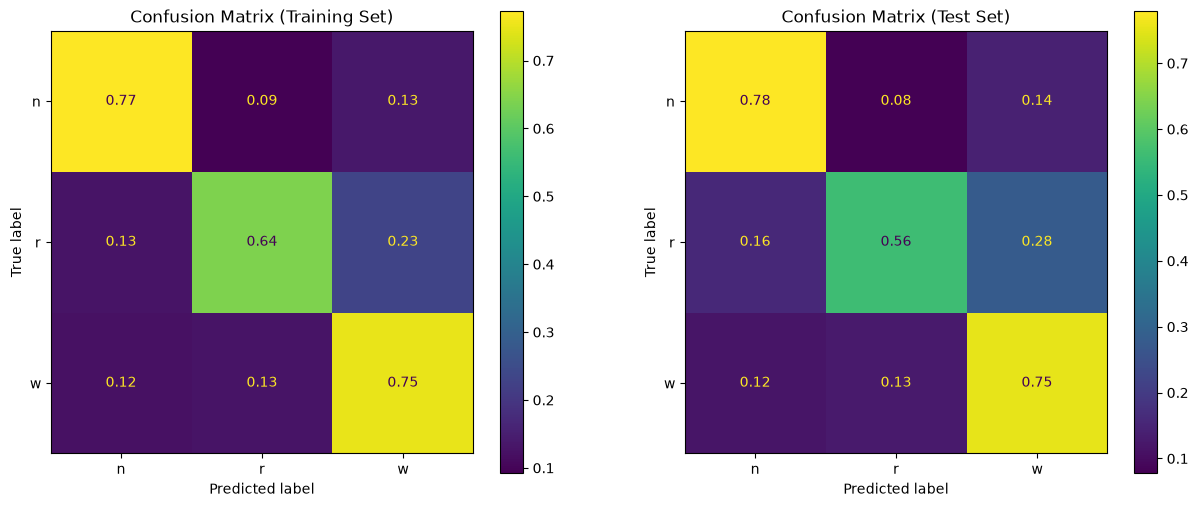

In [14]:
# Make predictions
train_prediction = DecisionTree_clf3.predict(X_train)
test_prediction = DecisionTree_clf3.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(Y_train, train_prediction)
test_accuracy = accuracy_score(Y_test, test_prediction)

# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Confusion matrix for the training set
cm_train = confusion_matrix(Y_train, train_prediction, normalize="true")
disp_train = ConfusionMatrixDisplay(
    confusion_matrix=cm_train, display_labels=DecisionTree_clf3.classes_
)
_ = disp_train.plot(ax=axs[0], values_format=".2f")
_ = axs[0].set_title("Confusion Matrix (Training Set)")

# Confusion matrix for the test set
cm_test = confusion_matrix(Y_test, test_prediction, normalize="true")
disp_test = ConfusionMatrixDisplay(
    confusion_matrix=cm_test, display_labels=DecisionTree_clf3.classes_
)
_ = disp_test.plot(ax=axs[1], values_format=".2f")
_ = axs[1].set_title("Confusion Matrix (Test Set)")

# Display accuracy for both sets
print("Accuracy on Training Set:", train_accuracy)
print("Accuracy on Test Set:", test_accuracy)

# Classification report for the training set
classification_metrics_train = classification_report(
    Y_train, train_prediction, output_dict=True, zero_division=0
)
report_df_train = pd.DataFrame(classification_metrics_train).transpose()
print("Classification Report for Training Set:")
print(report_df_train)

# Classification report for the test set
classification_metrics_test = classification_report(
    Y_test, test_prediction, output_dict=True, zero_division=0
)
report_df_test = pd.DataFrame(classification_metrics_test).transpose()
print("Classification Report for Test Set:")
print(report_df_test)

plt.show()

Q1.10: Compare results from model 2 and model 3. What are the pros and cons of each of them? 

**A1.10**
Here we see that model 3 has a lower train and test accuracy than model 2. However, looking carefully at the  other metrics, we notice that model 2 accuracy came from the fact that it focused on guessing the `w` class correctly but didn't really care about the 2 other classes (it only detects 22% of the `r` samples). This is fixed in model 3, it now has a decent score on all classes. `r` recall jumped from `0.22` to `0.56` and `n` recall also slightly improved.

To sum it up, Model 2 is better if you only care about detecting the `w` class or you mostly care about accuracy. If you care about still detecting the minority classes, Model 3 is more suited.

NOTE: Those models could be fine-tuned in order to enhance their ability to classify the state of a mouse. You can experiment with hyperparameters if you're interested in improving performance. However, we'll dive deeper into fine-tuning in the next notebook, where we'll explore Random Forests, a more powerful machine learning method. Random Forest is a popular technique that leverages the concept of ensemble learning. The fundamental idea behind it is to train multiple decision trees (like the ones in this notebook), each slightly different from the others, and then combine their outputs through a voting mechanism to make predictions. This ensemble approach typically leads to more robust and accurate predictions.